In [2]:
%matplotlib ipympl

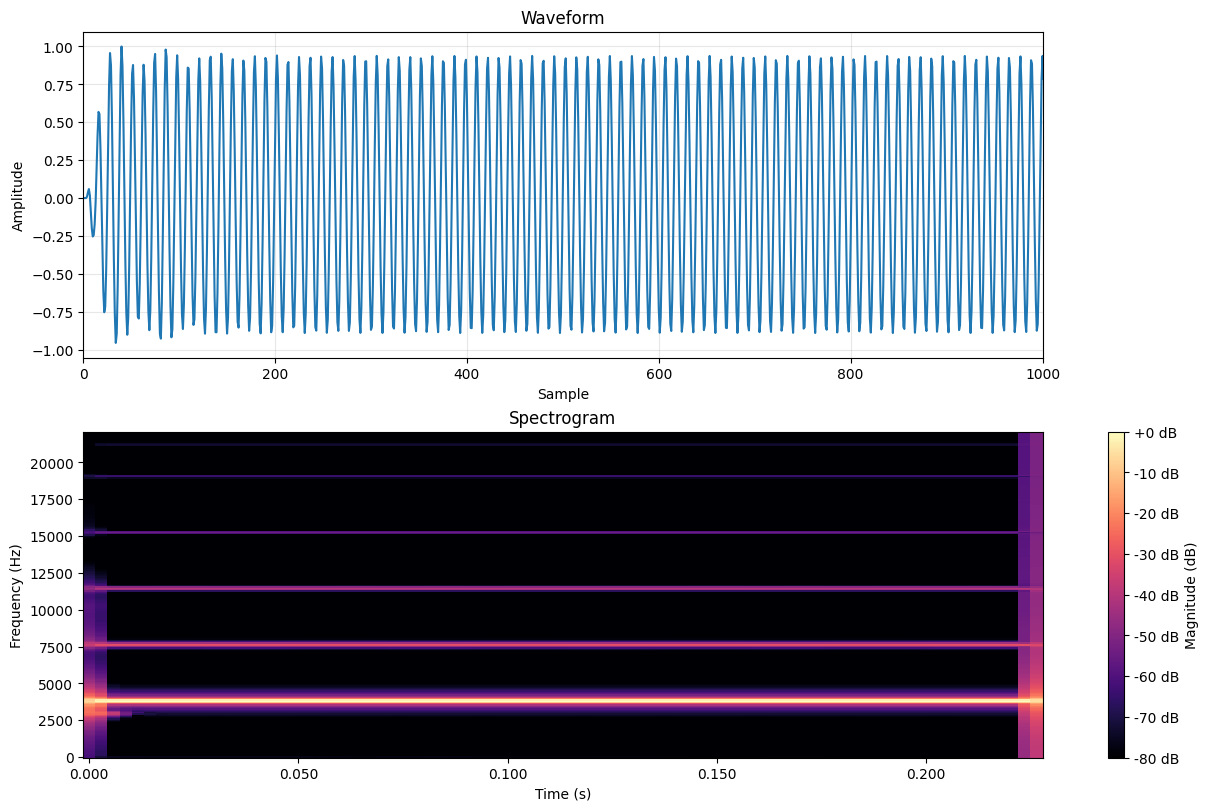

In [1]:
from matplotlib import pyplot as plt
import librosa
import librosa.display

from wavesongs_new.model import *

ZF_PARAMS = {
    "gm": 24e3,       # time scaling constant
    # ------------------------ Trachea ----------------------
    "L": 0.025,      # trachea length [m]
    "r": 0.65,       # reflection coeficient [adimensionelss]
    # ------------------------- OEC -------------------------
    "Ch": 1.43E-10,  # OEC Compliance [m^3/Pa]
    "MG": 20,        # Beak Inertance [Pa s^2/m^3 = kg/m^4]
    "MB": 1E4,       # Glottis Inertance [Pa s^2/m^3 = kg/m^4]
    "RB": 5E6,       # Beak Resistance [Pa s/m^3 = kg/m^4 s]
    "Rh": 24E3       # OEC Resistence [Pa s/m^3 = kg/m^4 s]
}


size = 10000
control_var = [0.5 * np.ones(size), 0.2 * np.ones(size)]
odes = ODESystem(organs=["syrinx", "trachea", "oec"], size=size, sr=44100, params=ZF_PARAMS)
song = odes._sound_source_trachea_oec_ode(control_var)




# Compute the spectrogram from the generated song.
song_stft = librosa.stft(song, n_fft=512, hop_length=128)
song_spectrogram = librosa.amplitude_to_db(np.abs(song_stft), ref=np.max)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)

axes[0].plot(song)
axes[0].set_title("Waveform")
axes[0].set_xlabel("Sample")
axes[0].set_ylabel("Amplitude")
axes[0].set_xlim(0, min(1000, len(song)))
axes[0].grid(True, alpha=0.3)

librosa.display.specshow(
    song_spectrogram,
    sr=odes.sr,
    hop_length=128,
    x_axis="time",
    y_axis="hz",
    ax=axes[1],
)
axes[1].set_title("Spectrogram")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Frequency (Hz)")
fig.colorbar(
    axes[1].collections[0],
    ax=axes[1],
    format="%+2.0f dB",
    label="Magnitude (dB)",
)

plt.show()

# Song().play()

In [ ]:
# create a grid of control variable valuesimport numpy as np
import matplotlib.pyplot as plt

from wavesongs_new.core import Song

size = 10000
control_var = [1.5 * np.ones(size), 0.2 * np.ones(size)]


odes = ODESystem(organs=["syrinx", "trachea", "oec"], size=size, sr=44100, params=ZF_PARAMS)

song_s = odes._sound_source_trachea_oec_ode(control_var)


def acoustical_descriptor(song, sr: int = 44100):
    # song = Song().create(s, sr=sr)
    f0 = song.f0_yin(song.s, sr=sr, n_fft=512, frame_length=512, hop_length=128, center=True, pad_mode="constant", trough_threshold=1.0, umbral_FF=1)
    sci = song.sci(f0)

    return [f0, sci]

    

def create_grid(
        odes,
        sr: int = 44100,
        dalpha: int = 100, alpha_lim : tuple = (-0.05, 0.2),
        dbeta: int = 100, beta_lim : tuple = (-0.2, 1.5),
    ):
    # conotrol variable arrays
    alphas = np.linspace(alpha_lim[0], alpha_lim[1], dalpha)
    betas = np.linspace(beta_lim[0], beta_lim[1], dbeta)
    # acoustical descriptors
    f0s = np.zeros((alphas.size, betas.size))
    scis = np.zeros((alphas.size, betas.size))

    for i in range(alphas.size):
        for j in range(betas.size):
            
            control_var = [
                alphas[i] * np.ones(size),
                betas[j] * np.ones(size)
            ]
            song_s = odes.ode()(control_var)
            
            song = Song().create(song_s, sr=sr)
            song.rstft(n_fft=512, hop_length=128, center=True, pad_mode="constant")

            [f0, sci] = acoustical_descriptor(song, sr=sr)

            f0s[i, j] = np.mean(f0)
            scis[i, j] = np.mean(sci)

    mesh = np.meshgrid(alphas, betas) # X, Y
    return [[alphas, betas], mesh, [f0s, scis]]
    
control_params, Z, acoustical_descriptors = create_grid(odes, dalpha=10, dbeta=10)


In [ ]:
%%timeit


np.save('ad.npy', acoustical_descriptors)
dalpha: int = 50
alpha_lim : tuple = (-0.05, 0.2)
dbeta: int = 50
beta_lim : tuple = (-0.2, 1.5)

alphas = np.linspace(alpha_lim[0], alpha_lim[1], dalpha)
betas = np.linspace(beta_lim[0], beta_lim[1], dbeta)

Z = np.meshgrid(alphas, betas) # X, Y

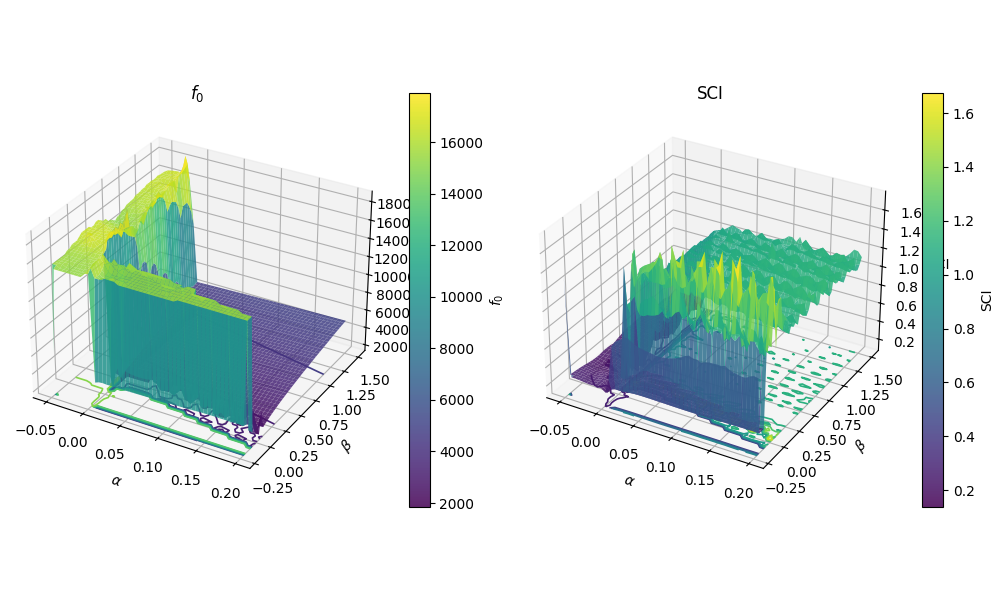

In [42]:
# Choose the plot type: "3d surface" or "heatmap".
plot_type = "3d surface"

X_plot, Y_plot = Z

if plot_type not in {"3d surface", "heatmap"}:
    raise ValueError("plot_type must be '3d surface' or 'heatmap'")

is_3d = plot_type == "3d surface"
fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 6),
    sharex=not is_3d,
    sharey=not is_3d,
    subplot_kw={"projection": "3d"} if is_3d else {},
    constrained_layout=True,
)

descriptor_labels = [r"$f_0$", "SCI"]
for ax, descriptor, label in zip(axes, acoustical_descriptors, descriptor_labels):
    descriptor_grid = descriptor.T
    contour_levels = np.linspace(
        np.nanmin(descriptor_grid),
        np.nanmax(descriptor_grid),
        12,
    )

    if is_3d:
        surface = ax.plot_surface(
            X_plot,
            Y_plot,
            descriptor_grid,
            cmap="viridis",
            edgecolor="none",
            alpha=0.85,
        )
        ax.contour(
            X_plot,
            Y_plot,
            descriptor_grid,
            levels=contour_levels,
            zdir="z",
            offset=np.nanmin(descriptor_grid),
            cmap="viridis",
            linewidths=1.2,
        )
        ax.set_zlabel(label)
        ax.set_zlim(np.nanmin(descriptor_grid), np.nanmax(descriptor_grid))
    else:
        surface = ax.contourf(
            X_plot,
            Y_plot,
            descriptor_grid,
            levels=contour_levels,
            cmap="viridis",
        )
        curves = ax.contour(
            X_plot,
            Y_plot,
            descriptor_grid,
            levels=contour_levels,
            colors="black",
            linewidths=0.7,
            alpha=0.7,
        )
        ax.clabel(curves, inline=True, fontsize=8, fmt="%.2g")

    ax.set_title(f"{label}") #  ({plot_type})
    ax.set_xlabel(r"$\alpha$")
    ax.set_ylabel(r"$\beta$")
    fig.colorbar(surface, ax=ax, shrink=0.7, label=label)

plt.show()

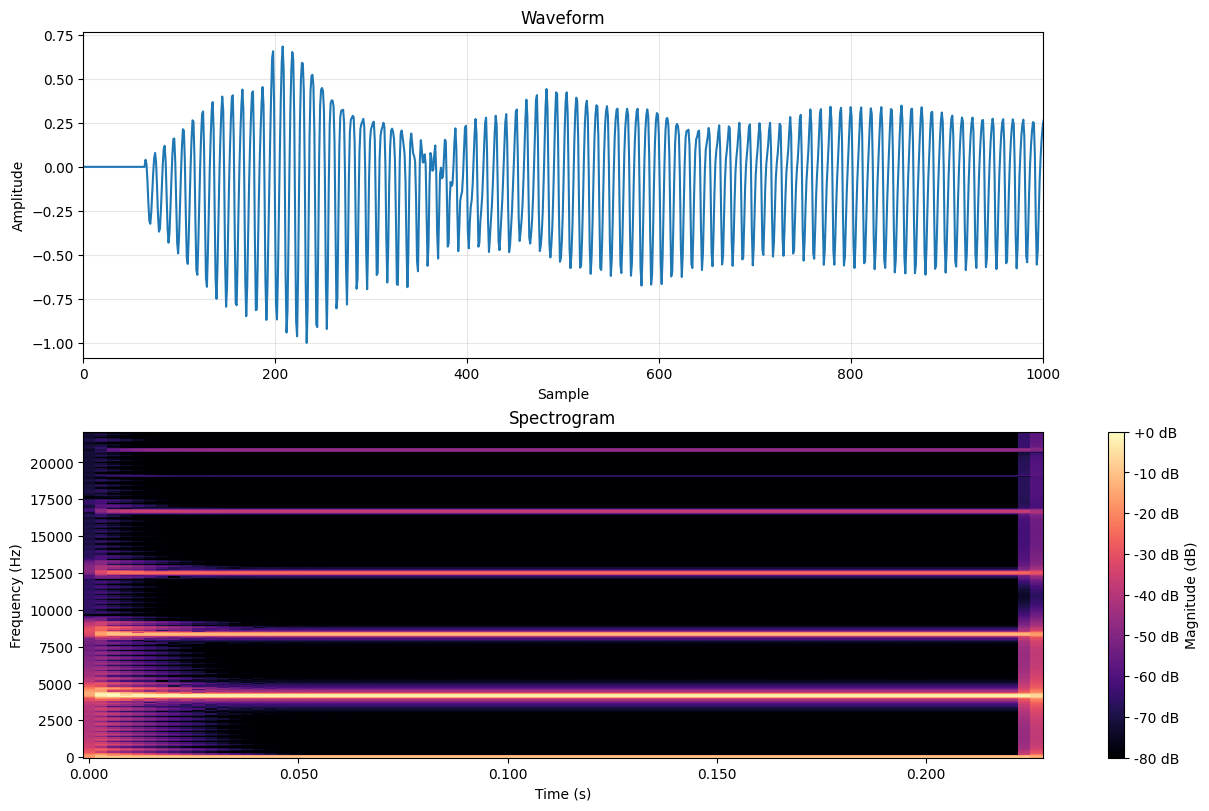

In [5]:
odes = ODESystem(organs=["syrinx", "trachea"], size=size, sr=44100, params=ZF_PARAMS)
song = odes.ode()(control_var)




# Compute the spectrogram from the generated song.
song_stft = librosa.stft(song, n_fft=512, hop_length=128)
song_spectrogram = librosa.amplitude_to_db(np.abs(song_stft), ref=np.max)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)

axes[0].plot(song)
axes[0].set_title("Waveform")
axes[0].set_xlabel("Sample")
axes[0].set_ylabel("Amplitude")
axes[0].set_xlim(0, min(1000, len(song)))
axes[0].grid(True, alpha=0.3)

librosa.display.specshow(
    song_spectrogram,
    sr=odes.sr,
    hop_length=128,
    x_axis="time",
    y_axis="hz",
    ax=axes[1],
)
axes[1].set_title("Spectrogram")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Frequency (Hz)")
fig.colorbar(
    axes[1].collections[0],
    ax=axes[1],
    format="%+2.0f dB",
    label="Magnitude (dB)",
)

plt.show()

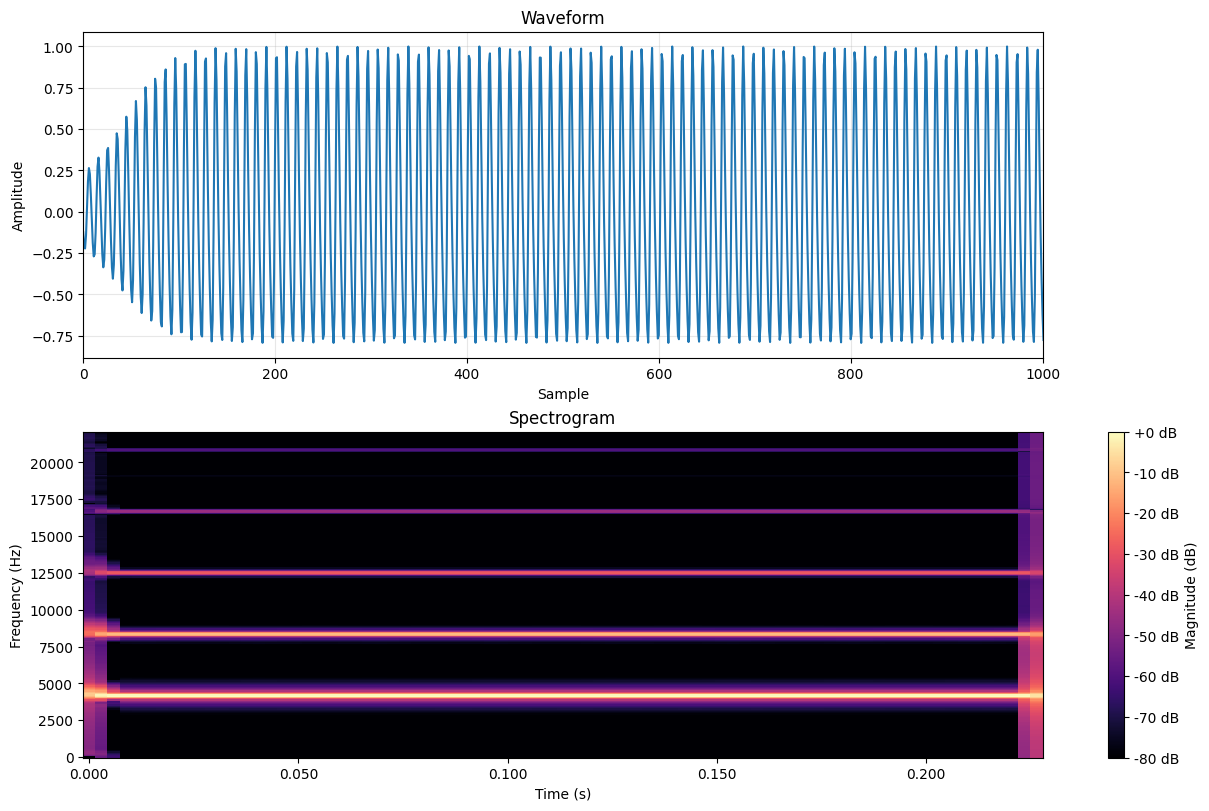

In [6]:
odes = ODESystem(organs=["syrinx"], size=size, sr=44100, params=ZF_PARAMS)
song = odes.ode()(control_var)




# Compute the spectrogram from the generated song.
song_stft = librosa.stft(song, n_fft=512, hop_length=128)
song_spectrogram = librosa.amplitude_to_db(np.abs(song_stft), ref=np.max)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)

axes[0].plot(song)
axes[0].set_title("Waveform")
axes[0].set_xlabel("Sample")
axes[0].set_ylabel("Amplitude")
axes[0].set_xlim(0, min(1000, len(song)))
axes[0].grid(True, alpha=0.3)

librosa.display.specshow(
    song_spectrogram,
    sr=odes.sr,
    hop_length=128,
    x_axis="time",
    y_axis="hz",
    ax=axes[1],
)
axes[1].set_title("Spectrogram")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Frequency (Hz)")
fig.colorbar(
    axes[1].collections[0],
    ax=axes[1],
    format="%+2.0f dB",
    label="Magnitude (dB)",
)

plt.show()

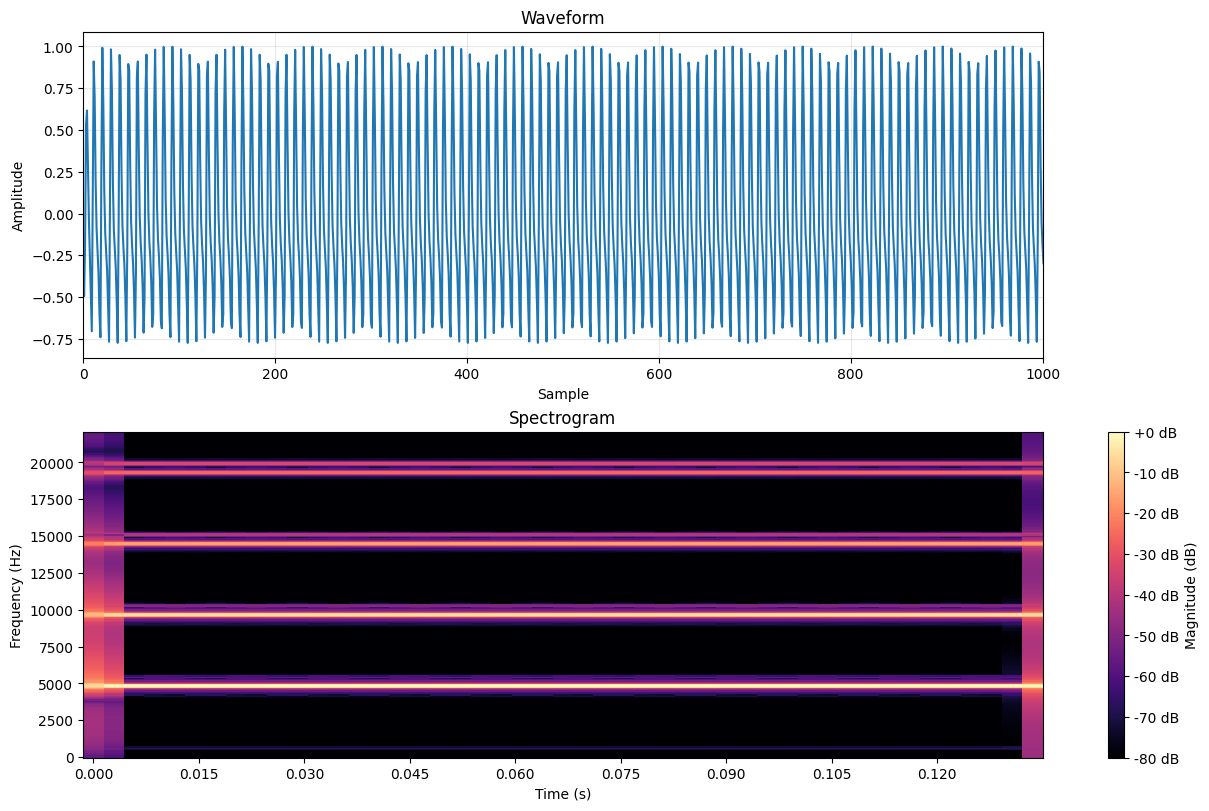

In [ ]:
from matplotlib import pyplot as plt
import librosa
import librosa.display

from wavesongs_new.model import *

ZF_PARAMS = {
    "gm": 40e3,       # time scaling constant
    # ------------------------ Trachea ----------------------
    "L": 0.025,      # trachea length [m]
    "r": 0.65,       # reflection coeficient [adimensionelss]
    # ------------------------- OEC -------------------------
    "Ch": 1.43E-10,  # OEC Compliance [m^3/Pa]
    "MG": 20,        # Beak Inertance [Pa s^2/m^3 = kg/m^4]
    "MB": 1E4,       # Glottis Inertance [Pa s^2/m^3 = kg/m^4]
    "RB": 5E6,       # Beak Resistance [Pa s/m^3 = kg/m^4 s]
    "Rh": 24E3       # OEC Resistence [Pa s/m^3 = kg/m^4 s]
}

size = 6000
control_var = [0.25 * np.ones(size), 0.2 * np.ones(size)]
odes = ODESystem(size=size, sr=44100, params=ZF_PARAMS)
song = odes.ode()(control_var)




# Compute the spectrogram from the generated song.
song_stft = librosa.stft(song, n_fft=512, hop_length=128)
song_spectrogram = librosa.amplitude_to_db(np.abs(song_stft), ref=np.max)

fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)

axes[0].plot(song)
axes[0].set_title("Waveform")
axes[0].set_xlabel("Sample")
axes[0].set_ylabel("Amplitude")
axes[0].set_xlim(0, min(1000, len(song)))
axes[0].grid(True, alpha=0.3)

librosa.display.specshow(
    song_spectrogram,
    sr=odes.sr,
    hop_length=128,
    x_axis="time",
    y_axis="hz",
    ax=axes[1],
)
axes[1].set_title("Spectrogram")
axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Frequency (Hz)")
fig.colorbar(
    axes[1].collections[0],
    ax=axes[1],
    format="%+2.0f dB",
    label="Magnitude (dB)",
)

plt.show()

In [8]:
from sympy import (
    symbols)

fs: list[str] = ["ys", "(-alpha-beta*xs-xs**3+xs**2)*gamma**2 - (xs+1)*gamma*xs*ys"]

symbols_str: str = "xs, ys, alpha, beta, gamma"
def correct_fstr(f: str) -> str:
        """
        Corrects the function string to ensure proper evaluation.
        """
        f = f.replace("xs", "x").replace("ys", "y").replace("alpha", '\\alpha').replace("beta", '\\beta').replace("gamma", '\\gamma').replace('**', '^')
        return f
# equation string evaluation
# print(correct_fstr(fs[0]))

# Equations symbols
symbols_list = symbols(symbols_str)
xs = symbols_list[0]
ys = symbols_list[1]
alpha = symbols_list[2]
beta = symbols_list[3]
gamma = symbols_list[4]

f1_eq = eval(fs[0])
f2_eq = eval(fs[1])

f1_eq**2, alpha


(ys**2, alpha)